# P1.3 — From Signal to Image: pulse sequences, spatial encoding and k-space

**Part:** Pass 1 — The big picture (notebook 3 of 5) · **Reading time:** ~45 min · **Previous:** [P1.2 The MRI Scanner](P1.2_The_MRI_Scanner.ipynb) · **Next:** [P1.4 Contrast and Image Quality](P1.4_Contrast_and_Image_Quality.ipynb) · **Refreshers you may want:** [Continuous FT & DFT](../refreshers/RM3_Continuous_FT_and_DFT.ipynb), [2D Fourier & images](../refreshers/RM6_2D_Fourier_and_Images.ipynb), [Complex numbers & rotations](../refreshers/RM2_Complex_Numbers_and_Rotations.ipynb)

**Why this notebook matters.** The receive coil delivers *one* voltage that is the sum of the signals of every voxel
in the body. How can a single signal become an image with 65 000 pixels? The answer — spatial encoding with gradients
and the concept of **k-space** — is the intellectual heart of MRI. Once you see that the MRI scanner literally measures
the **Fourier transform** of the image, one sample at a time, then resolution, field of view, scan time, fast imaging,
acceleration and most artifacts all become understandable.

## Learning goals

1. Read a simple **pulse-sequence diagram** (RF, $G_z$, $G_y$, $G_x$, ADC) and define $TE$ and $TR$.
2. Explain **slice selection**: RF pulse + gradient excite only a slab of thickness $\Delta z = BW_{rf}/(\bar\gamma G_{z,SS})$.
3. Explain **frequency encoding** and **phase encoding** and why a Fourier transform recovers positions.
4. Explain **k-space**: $\vec k(t) = \bar\gamma\int_0^t \vec G\,d\tau$, the signal is the Fourier transform of the image, each k-space sample is the weight of one **stripe pattern**.
5. Relate k-space sampling to the image: **FOV = 1/Δk**, **resolution = 1/(2 k_max)**; center = contrast, edges = detail.
6. Estimate the scan time of a basic sequence.

## Symbols used in this notebook

| Symbol | Meaning (plain words) | SI unit | Typical value / remark |
|---|---|---|---|
| $\vec r = [x,y,z]$ | position; $z$ along $B_0$ | m | |
| $t$, $\tau$ | time; $\tau$ = integration variable ("time so far") | s | |
| $\bar\gamma$ | gyromagnetic ratio | Hz/T | 42.58 MHz/T (¹H) |
| $B_0$ | main field | T | 3 T |
| $\vec G = [G_x, G_y, G_z]$ | gradient amplitudes | T/m | up to 40–80 mT/m |
| $f$ | precession frequency (relative to $f_0$ in the rotating frame) | Hz | |
| $G_{x,r}$ | readout (frequency-encoding) gradient | T/m | 5–30 mT/m |
| $G_{z,SS}$ | slice-select gradient | T/m | 5–20 mT/m |
| $BW_{rf}$ | bandwidth of the RF pulse (range of frequencies it excites) | Hz | 1–5 kHz |
| $T_{rf}$ | RF pulse duration | s | 1–3 ms |
| $TBW$ | time–bandwidth product $T_{rf}\cdot BW_{rf}$ (pulse-shape constant) | – | 2–12 |
| $\Delta z$ | slice thickness | m | 1–10 mm |
| $\theta$ | flip angle | rad / ° | |
| $\phi$ | phase of the transverse magnetization | rad | |
| $\vec k = [k_x,k_y,k_z]$ | k-space position = spatial frequency | m⁻¹ (cycles/m) | up to ~500 m⁻¹ |
| $\Delta k$ | spacing between k-space samples | m⁻¹ | ~4 m⁻¹ |
| $k_{max}$ | largest k sampled | m⁻¹ | |
| $FOV$ | field of view, $FOV = 1/\Delta k$ | m | 0.2–0.5 m |
| $\delta$ | spatial resolution (pixel size), $\delta = 1/(2k_{max})$ | m | 0.5–3 mm |
| $N$, $N_{read}$, $N_{PE}$ | matrix size; # readout samples; # phase-encode lines | – | 128–512 |
| $\Delta t$ | dwell time (time between ADC samples) | s | 2–20 µs |
| $BW_{read} = 1/\Delta t$ | receiver bandwidth (total); per pixel $BW_{read}/N_{read}$ | Hz | 30–250 kHz; 100–1000 Hz/pixel |
| $T_{read}$ | readout duration $N_{read}\Delta t$ | s | 1–10 ms |
| $t_y$ | duration of the phase-encode gradient lobe | s | ~0.5–1 ms |
| $m(\vec r)$ | the "image": transverse magnetization at the echo, as a function of position | a.u. | complex |
| $s(t)$ | received (demodulated) signal | V (a.u.) | complex |
| $M(\vec k)$ | k-space data = Fourier transform of $m$ (**clash:** not the magnetization $\vec M$!) | a.u. | |
| $\mathcal F$ | Fourier transform, $F(k)=\int f(x)e^{-i2\pi kx}dx$ | | |
| $TE$, $TR$ | echo time, repetition time | s | |
| $NEX$ | number of averages (excitations per k-space line) | – | 1–4 |
| $T_{scan}$ | total scan time | s | |

**Symbol clash:** $M(\vec k)$ (k-space data, Larson's notation) vs $\vec M$, $M_{xy}$ (magnetization). We say "k-space data" whenever
we mean the former.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(".."))   # make ../mri_tools.py importable
import numpy as np
import matplotlib.pyplot as plt
import mri_tools as mt
mt.setup_plots()
%matplotlib inline

## 1. The pulse sequence: the "musical score" of a scan

A **pulse sequence** is the timed recipe that the scanner plays: when to transmit RF, which gradients to switch on,
and when to record (ADC = data acquisition window). It is drawn as a **pulse-sequence diagram**, one row per channel:

![Pulse sequence diagram](../images/pulse_sequence-diagram-annotated.png)

*A 2D gradient-echo sequence (from Larson's book). Rows: RF pulse; $G_z$ (slice select + refocusing lobe); $G_y$ (phase
encoding, a "table" of different amplitudes); $G_x$ (frequency encoding: negative prewinder, then the readout lobe);
ADC/DAQ (sampling window).*

Two times define the timing:

* **Echo time $TE$**: from the center of the RF pulse to the moment the **center of k-space** is recorded (the echo).
* **Repetition time $TR$**: time between successive excitations. The block is repeated $N_{PE}$ times (once per
  phase-encode step), each time with a different $G_y$ amplitude.

The plan for this notebook: **slice selection** picks a plane (§3), **frequency encoding** labels $x$ (§2),
**phase encoding** labels $y$ (§4), and **k-space** (§5) unifies everything.

➡️ **Go deeper:** [C1 Pulse Sequence](../pass2_deep_dive/C1_Pulse_Sequence.ipynb) · [B1 MRI System](../pass2_deep_dive/B1_MRI_System.ipynb)

## 2. Frequency encoding: position → pitch

### 2.1 The piano-chord picture of Fourier analysis

> **🧭 Intuition (piano chord):** when you play a chord, your ear receives *one* pressure wave, the sum of several
> notes. Yet a trained ear (or the Fourier transform) can tell *which* notes are playing and *how loudly*. If each piano
> key corresponded to one position in the body, hearing the chord would tell you how much tissue is at each position.
> That is exactly MRI frequency encoding.

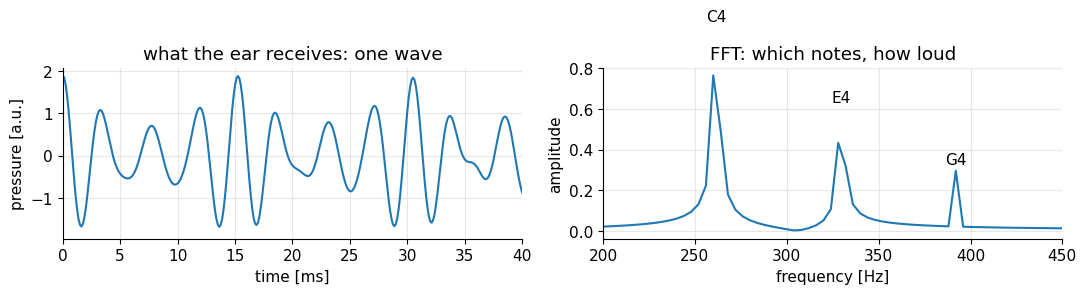

In [2]:
fs, T = 8000, 0.25                                    # sample rate [Hz], duration [s]
t = np.arange(int(fs*T))/fs
notes = {"C4": (261.6, 1.0), "E4": (329.6, 0.6), "G4": (392.0, 0.3)}   # frequency [Hz], loudness
chord = sum(a*np.cos(2*np.pi*f*t) for f, a in notes.values())
spec = np.abs(np.fft.rfft(chord))/len(t)*2
freqs = np.fft.rfftfreq(len(t), 1/fs)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.3))
ax[0].plot(t*1e3, chord); ax[0].set(xlim=(0, 40), xlabel="time [ms]", ylabel="pressure [a.u.]", title="what the ear receives: one wave")
ax[1].plot(freqs, spec); ax[1].set(xlim=(200, 450), xlabel="frequency [Hz]", ylabel="amplitude", title="FFT: which notes, how loud")
for name, (f, a) in notes.items(): ax[1].text(f, a + 0.03, name, ha="center")
plt.tight_layout(); plt.show()

*Interpretation:* the time signal looks messy, but its Fourier transform shows three clean peaks with the right
amplitudes. You know the DFT/FFT; for MRI we also need the *continuous* Fourier transform and its 2D version — see the
refreshers [RM3](../refreshers/RM3_Continuous_FT_and_DFT.ipynb) and [RM6](../refreshers/RM6_2D_Fourier_and_Images.ipynb).

### 2.2 A gradient turns position into frequency

With a readout gradient $G_{x,r}$ switched on during acquisition, a spin at position $x$ precesses (in the rotating
frame) at

$$f(x) = \bar\gamma\,G_{x,r}\,x .$$

*In words:* the offset frequency is proportional to position: each $x$ "plays its own note".
$\bar\gamma$ in Hz/T, $G_{x,r}$ in T/m, $x$ in m, $f$ in Hz. E.g. 10 mT/m gives 426 Hz per mm.

The coil receives the sum over all positions, $s(t) = \sum_x m(x)\,e^{-i2\pi f(x) t}$ — a "chord" whose note
amplitudes are the amounts of magnetization $m(x)$ at each position. The FFT un-mixes it.

Below we simulate a 1D object (three blocks with different amounts of water), sum the signals of all positions
explicitly, and then Fourier-transform the result. The readout parameters are realistic: FOV 24 cm, 256 samples,
dwell time 8 µs.

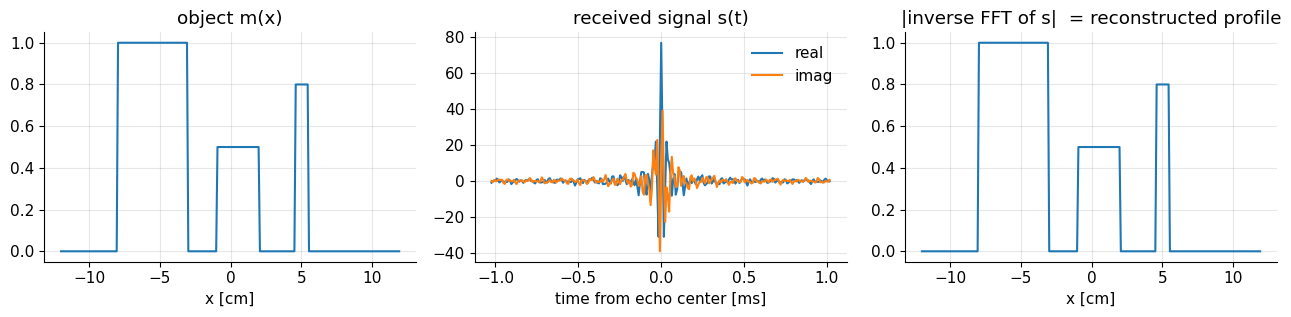

readout gradient 12.2 mT/m, BW = 125 kHz (+-62.5 kHz), 488 Hz/pixel, readout duration 2.05 ms, pixel size 0.94 mm


In [3]:
N = 256
FOV = 0.24                                        # field of view [m]
dx = FOV / N                                      # pixel size [m]
x = (np.arange(N) - N//2) * dx                    # positions [m]
m = np.zeros(N)                                   # the 1D "object" m(x)
m[(x > -0.08) & (x < -0.03)] = 1.0
m[(x > -0.01) & (x < 0.02)] = 0.5
m[(x > 0.045) & (x < 0.055)] = 0.8

dt = 8e-6                                         # dwell time [s]
BW_read = 1/dt                                    # receiver bandwidth [Hz]
G_read = BW_read / (mt.GAMMA_BAR * FOV)           # gradient so that the FOV spans exactly BW_read [T/m]
t_read = (np.arange(N) - N//2) * dt               # sample times relative to the echo center [s]
# Signal = sum over positions of m(x) * exp(-i 2 pi f(x) t), with f(x) = gamma_bar * G * x
s = (m[None, :] * np.exp(-1j*2*np.pi*mt.GAMMA_BAR*G_read*x[None, :]*t_read[:, None])).sum(axis=1)

m_rec = mt.ifftc(s) * np.sqrt(N) / N              # inverse (centered) DFT recovers the profile; scale to object units

fig, ax = plt.subplots(1, 3, figsize=(13, 3.3))
ax[0].plot(x*100, m); ax[0].set(xlabel="x [cm]", title="object m(x)")
ax[1].plot(t_read*1e3, s.real, label="real"); ax[1].plot(t_read*1e3, s.imag, label="imag"); ax[1].legend()
ax[1].set(xlabel="time from echo center [ms]", title="received signal s(t)")
ax[2].plot(x*100, np.abs(m_rec)); ax[2].set(xlabel="x [cm]", title="|inverse FFT of s|  = reconstructed profile")
plt.tight_layout(); plt.show()
print(f"readout gradient {G_read*1e3:.1f} mT/m, BW = {BW_read/1e3:.0f} kHz (+-{BW_read/2e3:.1f} kHz), "
      f"{BW_read/N:.0f} Hz/pixel, readout duration {N*dt*1e3:.2f} ms, pixel size {dx*1e3:.2f} mm")

*Interpretation:* the signal is largest in the middle of the readout, where all positions are momentarily in phase —
this is the **gradient echo** (created by the negative "prewinder" lobe before the readout, see §5). The inverse FFT
recovers the object exactly: each frequency bin is one pixel.

> **⚠️ Common confusion:** with the MRI convention $e^{-i2\pi f t}$ for precession, the signal is the *forward* Fourier
> transform of the object, and the image is the *inverse* transform of the data. Some books use the opposite sign; only
> the image orientation changes.

> **🔧 Engineering reality:** the dwell time sets the receiver bandwidth ($BW_{read}=1/\Delta t$). A wide bandwidth
> means a short readout (fast, little $T_2^*$ decay, small distortions) but more noise (P1.4); a narrow bandwidth
> collects less noise but makes the image more sensitive to off-resonance (chemical shift, P1.5). A typical compromise
> is a few hundred Hz per pixel.

➡️ **Go deeper:** [F1 Spatial Encoding](../pass2_deep_dive/F1_Spatial_Encoding.ipynb) · [C2 MRI Signal Equation](../pass2_deep_dive/C2_MRI_Signal_Equation.ipynb) · [RM3 Continuous FT & DFT](../refreshers/RM3_Continuous_FT_and_DFT.ipynb)

## 3. Slice selection: exciting only one plane

Frequency encoding gives one dimension. To image a 2D slice through a 3D body we first make sure only that slice is
excited. Switch on a gradient $G_{z,SS}$ *during* the RF pulse: now the Larmor frequency varies along $z$, and a pulse
containing only a narrow band of frequencies $BW_{rf}$ is "in tune" (P1.1 resonance) only with the spins in a slab:

$$\Delta z = \frac{BW_{rf}}{\bar\gamma\,G_{z,SS}} .$$

*In words:* slice thickness = (range of frequencies in the pulse) ÷ (frequency change per metre). Thinner slices need a
narrower-band (longer) pulse or a stronger gradient. $\Delta z$ in m, $BW_{rf}$ in Hz, $G_{z,SS}$ in T/m.
Shifting the RF frequency by $f_{off}$ moves the slice to $z_{off} = f_{off}/(\bar\gamma G_{z,SS})$.

![Slice selection intuition](../images/Slice_Selection-intuition.png)

The ideal pulse would excite a perfect rectangle in frequency. A rectangle in frequency is the Fourier transform of a
**sinc** function in time, so slice-selective pulses are (windowed) sincs. Let's Bloch-simulate a 90° sinc pulse with
$T_{rf}$ = 2 ms and $TBW$ = 4 (so $BW_{rf}$ = 2 kHz) under $G_{z,SS}$ = 10 mT/m, followed by a negative gradient lobe of
half the area that re-phases the slice.

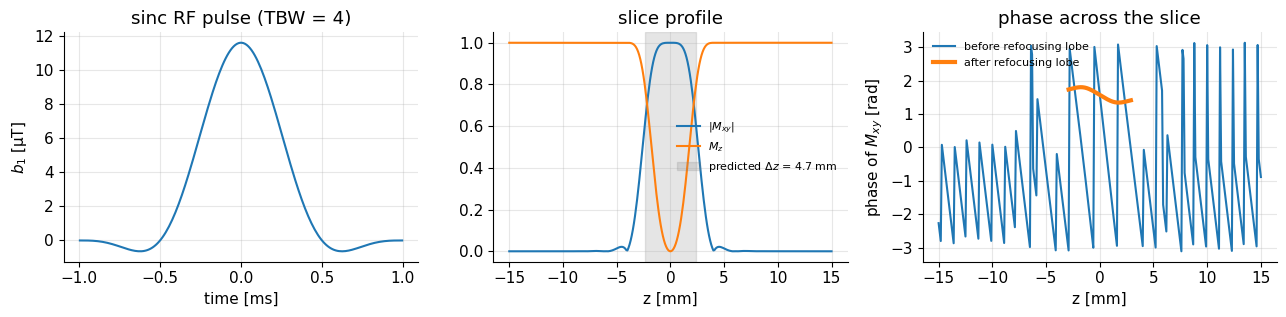

In [4]:
dt = 10e-6                                        # 10 us steps
T_rf, TBW = 2e-3, 4
BW_rf = TBW / T_rf                                # [Hz]
t_rf = (np.arange(int(T_rf/dt)) + 0.5)*dt - T_rf/2
shape = np.sinc(t_rf*BW_rf) * np.hanning(t_rf.size)              # Hann-windowed sinc
b1 = shape / (mt.GAMMA*shape.sum()*dt) * np.pi/2                  # scale to a 90 deg flip angle [T]
Gss = 10e-3                                       # slice-select gradient [T/m]

n_rf, n_ref = t_rf.size, int(1e-3/dt)             # refocusing lobe: -Gss for 1 ms (half the area)
B1_all = np.concatenate([b1, np.zeros(n_ref)]).astype(complex)
G_all = np.zeros((n_rf + n_ref, 3)); G_all[:n_rf, 2] = Gss; G_all[n_rf:, 2] = -Gss
z = np.linspace(-0.015, 0.015, 301)               # spin positions along z [m]
r = np.stack([0*z, 0*z, z], axis=1)
t, M = mt.bloch_simulate(B1=B1_all, dt=dt, G=G_all, r=r)
Mxy_end = M[-1, :, 0] + 1j*M[-1, :, 1]
Mxy_mid = M[n_rf, :, 0] + 1j*M[n_rf, :, 1]        # right after the RF pulse, before refocusing

fig, ax = plt.subplots(1, 3, figsize=(13, 3.3))
ax[0].plot(t_rf*1e3, b1*1e6); ax[0].set(xlabel="time [ms]", ylabel="$b_1$ [µT]", title="sinc RF pulse (TBW = 4)")
ax[1].plot(z*1e3, np.abs(Mxy_end), label="$|M_{xy}|$"); ax[1].plot(z*1e3, M[-1, :, 2], label="$M_z$")
dz = BW_rf/(mt.GAMMA_BAR*Gss)
ax[1].axvspan(-dz/2*1e3, dz/2*1e3, color="gray", alpha=0.2, label=f"predicted $\\Delta z$ = {dz*1e3:.1f} mm")
ax[1].set(xlabel="z [mm]", title="slice profile"); ax[1].legend(fontsize=8)
ax[2].plot(z*1e3, np.angle(Mxy_mid), label="before refocusing lobe")
ax[2].plot(z*1e3, np.where(np.abs(Mxy_end) > 0.3, np.angle(Mxy_end), np.nan), lw=3, label="after refocusing lobe")
ax[2].set(xlabel="z [mm]", ylabel="phase of $M_{xy}$ [rad]", title="phase across the slice"); ax[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

*Interpretation:* only spins within ±2.3 mm of the center are tipped; outside, $M_z$ stays at 1. Right after the pulse
the phase winds rapidly across the slice (left half of the pulse's gradient "dephases" the spins); the negative
refocusing lobe unwinds it, leaving a nearly flat phase so that the whole slice contributes coherently.

> **🔧 Engineering reality:** thin slices need strong gradients or long pulses; long pulses lengthen $TE$, and short,
> high-bandwidth pulses need high $B_1$ (SAR!). Real slice profiles are never perfectly rectangular, so neighbouring
> slices are often separated by a small gap or acquired interleaved.

➡️ **Go deeper:** [E2 Slice Selection](../pass2_deep_dive/E2_Slice_Selection.ipynb) · [E1 RF Pulses](../pass2_deep_dive/E1_RF_Pulses.ipynb) · [E3 RF Pulse Design](../pass2_deep_dive/E3_RF_Pulse_Design.ipynb) · [RM5 Fourier pairs & sampling](../refreshers/RM5_Fourier_Pairs_and_Sampling.ipynb) (rect ↔ sinc)

## 4. Phase encoding: the second dimension

We can't frequency-encode $y$ at the same time as $x$ (a gradient along a diagonal would only give a single, rotated
direction). Instead, *before* the readout we switch on a gradient $G_y$ for a short time $t_y$. While it is on, spins at
different $y$ precess at different rates, so when it is switched off they have accumulated a **phase**

$$\phi(y) = -2\pi\,\bar\gamma\,G_y\,t_y\,y .$$

*In words:* the phase twist is proportional to position $y$ and to the gradient area $G_y t_y$. This leaves a
"twist" — a stripe pattern — across the object in $y$, *without* changing frequencies during the readout.
(The minus sign is the clockwise-precession convention; $\phi$ in rad.)

One phase-encode step gives one twist. We repeat the excitation $N_{PE}$ times with $N_{PE}$ different values of
$G_y$, each time reading out with frequency encoding. Let's look at what a few phase-encode steps do to an object:

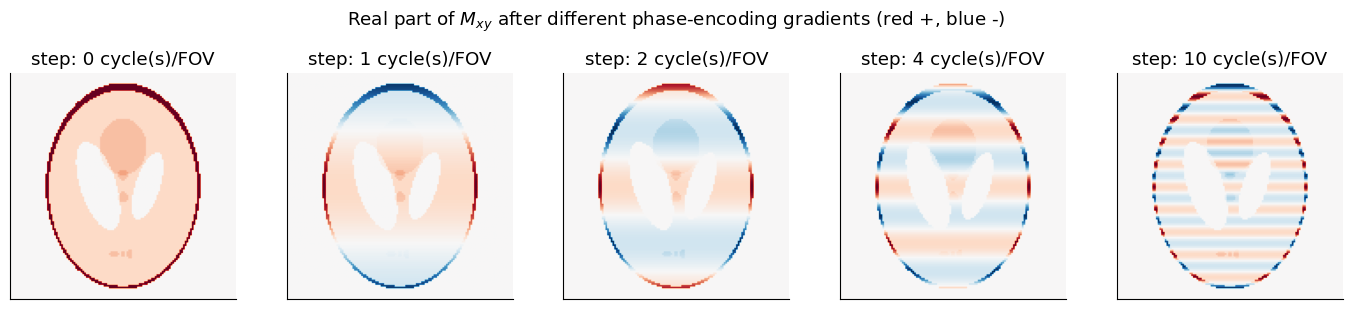

In [5]:
img = mt.shepp_logan(128)
Ny = img.shape[0]
y = (np.arange(Ny) - Ny//2)[:, None] / Ny          # y in units of the FOV (-0.5..0.5)
fig, ax = plt.subplots(1, 5, figsize=(14, 3))
for a, n_cycles in zip(ax, [0, 1, 2, 4, 10]):
    twisted = img * np.exp(-1j*2*np.pi*n_cycles*y)  # phase twist with n_cycles across the FOV
    mt.show_image(twisted.real, ax=a, cmap="RdBu_r", vmin=-1, vmax=1, title=f"step: {n_cycles} cycle(s)/FOV")
plt.suptitle("Real part of $M_{xy}$ after different phase-encoding gradients (red +, blue -)", y=1.02)
plt.tight_layout(); plt.show()

*Interpretation:* each phase-encode step multiplies the object by a different stripe pattern along $y$. The coil then
measures the *total* signal of each "striped" object — which is exactly one Fourier coefficient (how much of that
stripe frequency the object contains). Measuring many different stripes and inverse-Fourier-transforming recovers $y$.

| ![Phase encoding steps](../images/phase_encoding_steps.gif) | ![Frequency and phase encoding](../images/frequency_phase_encoding-simple-Mxy.gif) |
| :-: | :-: |
| Phase-encoding steps: increasing twist | Frequency + phase encoding of $M_{xy}$ during one readout |

➡️ **Go deeper:** [F1 Spatial Encoding](../pass2_deep_dive/F1_Spatial_Encoding.ipynb) · [RM2 Complex numbers & rotations](../refreshers/RM2_Complex_Numbers_and_Rotations.ipynb)

## 5. k-space: the unifying picture

### 5.1 Definition

Frequency encoding and phase encoding are really the same thing: in both cases a gradient makes the phase vary
linearly across the object. What matters at any time is the *accumulated gradient area*. We call it the **k-space
position**

$$\vec k(t) = \bar\gamma \int_0^t \vec G(\tau)\,d\tau .$$

*In words:* $\vec k$ is the running total of all gradient areas since the excitation, times $\bar\gamma$. Its unit is
cycles per metre (m⁻¹): $\vec k$ tells you how many cycles the phase twist makes per metre — a **spatial frequency**.
$\vec G$ in T/m, $\tau$ the integration variable [s].

With this, the signal of the whole (excited slice of the) object $m(\vec r)$ is

$$s(t) = \int m(\vec r)\,e^{-i2\pi\,\vec k(t)\cdot\vec r}\,d\vec r = M\bigl(\vec k(t)\bigr).$$

*In words:* at each moment, the coil measures the object multiplied by the stripe pattern $e^{-i2\pi\vec k\cdot\vec r}$
and summed over all positions. That is the definition of the **Fourier transform** $M(\vec k)$ of the image, evaluated at
$\vec k(t)$. **The MRI scanner measures the Fourier transform of the image, one point at a time.** The gradients steer
*where* in k-space we are; the ADC decides *when* we take a sample. ($M(\vec k)$ here is k-space data, not magnetization.)

### 5.2 Every k-space point is a stripe pattern — the "recipe of stripes"

> **🧭 Intuition (recipe):** every image can be written as a sum of stripe patterns of different spacing, direction and
> shift (2D Fourier analysis). k-space is the *recipe*: one entry per stripe, saying how much of it (magnitude) and
> where its crests sit (phase). The center of k-space is the "flat" pattern (average brightness); farther out are finer
> stripes; the direction of $\vec k$ is the direction across the stripes.

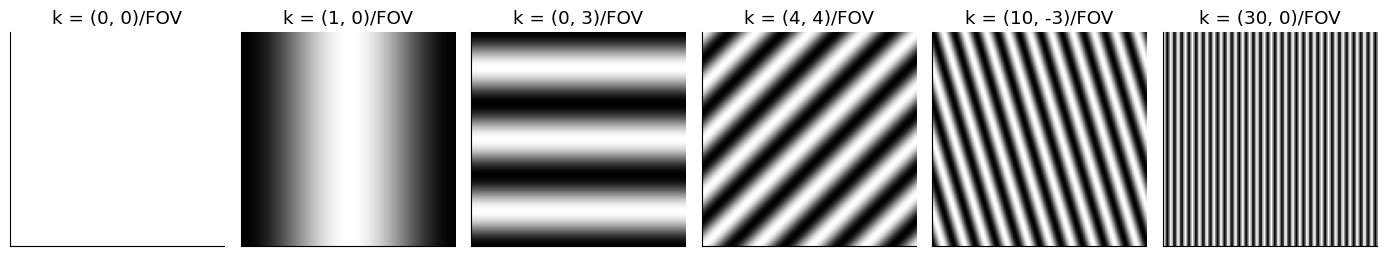

In [6]:
n = 128
yy, xx = np.mgrid[-n//2:n//2, -n//2:n//2] / n       # coordinates in units of the FOV
examples = [(0, 0), (1, 0), (0, 3), (4, 4), (10, -3), (30, 0)]   # (kx, ky) in cycles per FOV
fig, ax = plt.subplots(1, len(examples), figsize=(14, 2.6))
for a, (kx, ky) in zip(ax, examples):
    mt.show_image(np.cos(2*np.pi*(kx*xx + ky*yy)), ax=a, vmin=-1, vmax=1, title=f"k = ({kx}, {ky})/FOV")
plt.tight_layout(); plt.show()

Now the real thing: the 2D FFT of a head phantom gives its k-space. We then rebuild the image from only the center of
k-space or only the edges.

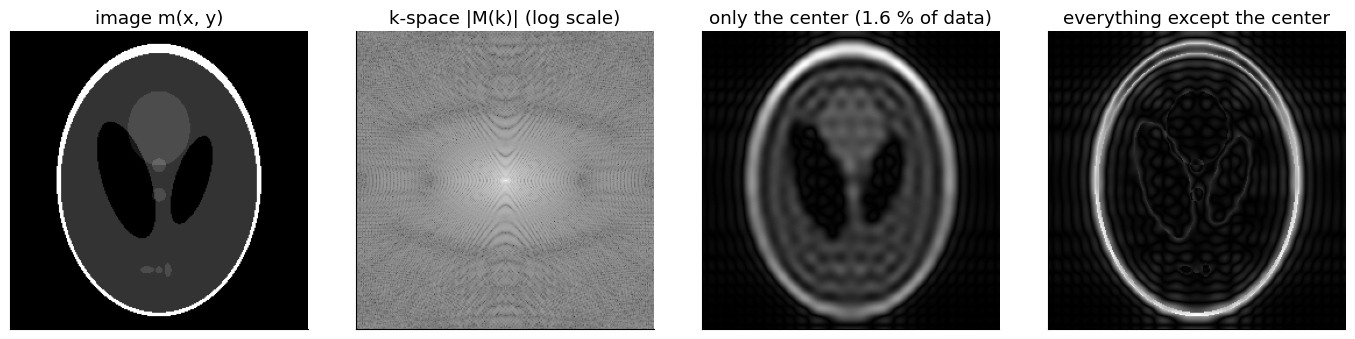

fraction of signal energy in the central 32x32: 75.1 %


In [7]:
img = mt.shepp_logan(256)
K = mt.fft2c(img)                                    # image -> k-space (forward FT, MRI sign convention)
N = img.shape[0]
ky, kx = np.mgrid[-N//2:N//2, -N//2:N//2]
center = (np.abs(kx) < 16) & (np.abs(ky) < 16)       # central 32 x 32 of 256 x 256 samples (1.6 %)

fig, ax = plt.subplots(1, 4, figsize=(14, 3.4))
mt.show_image(img, ax=ax[0], title="image m(x, y)")
mt.show_kspace(K, ax=ax[1], title="k-space |M(k)| (log scale)")
mt.show_image(mt.ifft2c(K*center), ax=ax[2], title="only the center (1.6 % of data)")
mt.show_image(mt.ifft2c(K*~center), ax=ax[3], title="everything except the center")
plt.tight_layout(); plt.show()
print(f"fraction of signal energy in the central 32x32: {np.sum(np.abs(K[center])**2)/np.sum(np.abs(K)**2)*100:.1f} %")

*Interpretation:* k-space does not look like the image at all — every k-space point contains information from the
*whole* object. The tiny central region holds most of the energy and determines the overall brightness and
**contrast**; the outer region holds the **edges and fine detail**. This is why the **echo time** is defined as the time
when the k-space center is acquired: the contrast is set by what the magnetization was doing at that moment.

> **⚠️ Common confusion:** there is *no* one-to-one correspondence between a k-space point and an image pixel. Damage
> a single k-space point (e.g. a noise spike) and you get a stripe pattern across the *whole* image (P1.5).

Here is a progressive reconstruction: we use more and more of k-space, from the center outwards.

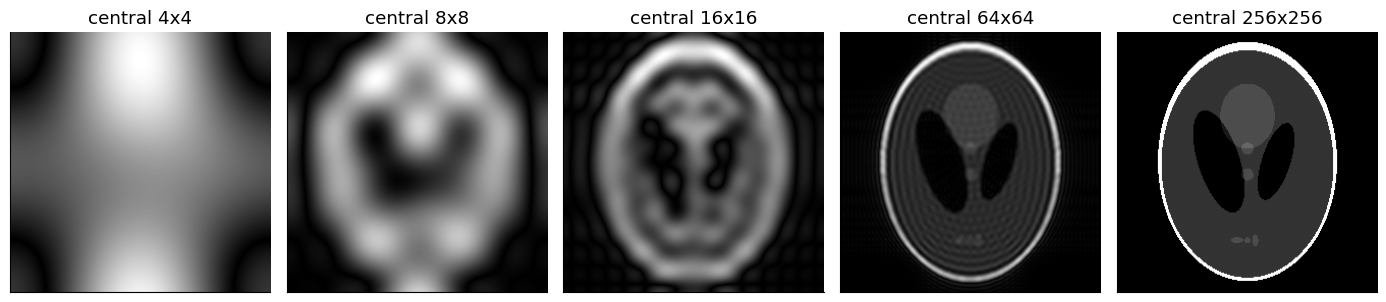

In [8]:
fig, ax = plt.subplots(1, 5, figsize=(14, 3))
for a, half in zip(ax, [2, 4, 8, 32, 128]):
    keep = (np.abs(kx) < half) & (np.abs(ky) < half)
    mt.show_image(mt.ifft2c(K*keep), ax=a, title=f"central {2*half}x{2*half}")
plt.tight_layout(); plt.show()

*Interpretation:* with very few samples we see a blurry blob with the right overall shape; each extension of k-space
adds finer detail. The outermost samples sharpen edges. (The ripples near edges in the intermediate images are
**Gibbs ringing**, from cutting k-space off abruptly — P1.5.)

| ![Center-out acquisition](../images/image_formation_centerout_lines.gif) | ![Random-order acquisition](../images/image_formation_random_lines.gif) |
| :-: | :-: |
| Filling k-space line by line, center-out | Same lines in random order: same final image |

The same is true for real MRI data. Here is a raw k-space data set of a sagittal T1-weighted spin-echo scan of the head
(from Larson's repository), and its image:

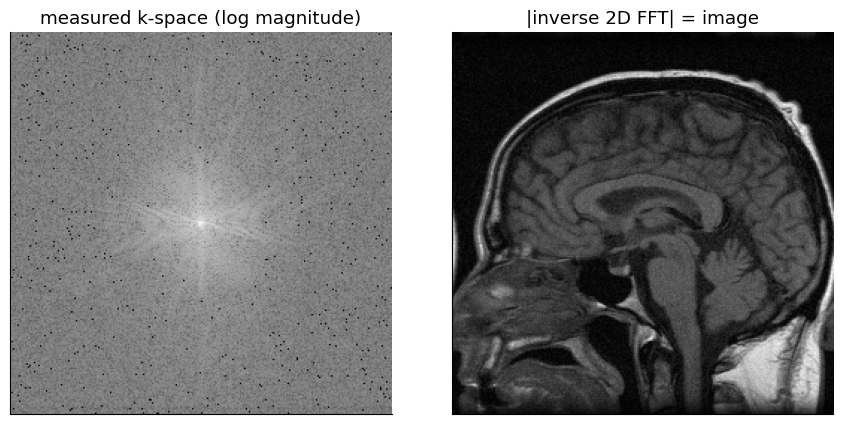

In [9]:
from scipy.io import loadmat
kdata = loadmat("../data/se_t1_sag_data.mat")["data"]     # 256 x 256 complex k-space, measured
im = mt.ifft2c(kdata)
fig, ax = plt.subplots(1, 2, figsize=(9, 4.3))
mt.show_kspace(kdata, ax=ax[0], title="measured k-space (log magnitude)")
mt.show_image(im, ax=ax[1], title="|inverse 2D FFT| = image")
plt.tight_layout(); plt.show()

*Interpretation:* the reconstruction of a basic Cartesian MRI scan really *is* one inverse 2D FFT (per coil, plus
coil combination and some corrections).

➡️ **Go deeper:** [F2 K-space](../pass2_deep_dive/F2_K-space.ipynb) · [C2 MRI Signal Equation](../pass2_deep_dive/C2_MRI_Signal_Equation.ipynb) · [F3 Image Reconstruction](../pass2_deep_dive/F3_Image_Reconstruction.ipynb) · [RM6 2D Fourier & images](../refreshers/RM6_2D_Fourier_and_Images.ipynb)

## 6. Moving through k-space: trajectories

Because $\vec k(t)$ is the running integral of the gradients, gradient waveforms *steer* through k-space like a pen:
a positive $G_x$ moves right, a negative one moves left, $G_y$ moves up/down, and no gradient means standing still.
In the standard **Cartesian** gradient-echo sequence, each TR:

1. the phase-encode lobe $G_y$ moves to the row $k_y$ (different every TR),
2. the negative readout prewinder moves to the left edge $-k_{x,max}$,
3. the readout gradient sweeps along the row while the ADC samples (the echo occurs when $k_x$ passes 0).

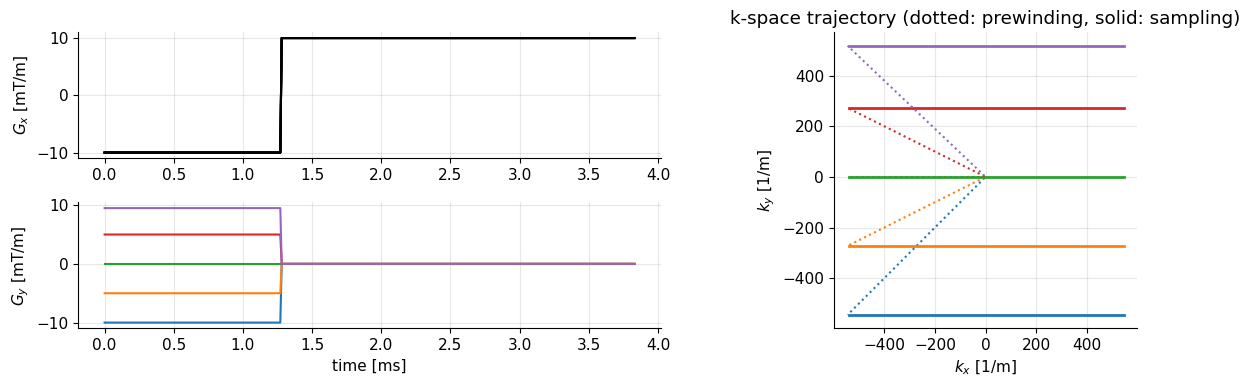

In [10]:
dt = 10e-6
Gr, Tr = 10e-3, 2.56e-3                     # readout gradient [T/m] and readout duration [s]
n_pre, n_read = int(Tr/2/dt), int(Tr/dt)
ky_max = mt.GAMMA_BAR * Gr * Tr / 2         # make k-space square: ky_max = kx_max  [1/m]
t_pe = Tr/2                                 # phase-encode lobe duration (same time as the prewinder) [s]

fig = plt.figure(figsize=(13, 4))
axg = [fig.add_subplot(2, 2, 1), fig.add_subplot(2, 2, 3)]
axk = fig.add_subplot(1, 2, 2)
for j, frac in enumerate([-1, -0.5, 0, 0.5, 0.95]):
    Gy_amp = frac * ky_max / (mt.GAMMA_BAR * t_pe)                # gradient that reaches this ky
    Gx = np.concatenate([np.full(n_pre, -Gr), np.full(n_read, Gr)])
    Gy = np.concatenate([np.full(n_pre, Gy_amp), np.zeros(n_read)])
    kx_t = mt.GAMMA_BAR * np.cumsum(Gx) * dt                       # k(t) = gamma_bar * integral of G
    ky_t = mt.GAMMA_BAR * np.cumsum(Gy) * dt
    tt = np.arange(Gx.size)*dt*1e3
    axg[0].plot(tt, Gx*1e3, color="k"); axg[1].plot(tt, Gy*1e3, label=f"line {j}")
    axk.plot(kx_t[:n_pre], ky_t[:n_pre], ":", color=f"C{j}")      # dotted: moving to the start (no sampling)
    axk.plot(kx_t[n_pre:], ky_t[n_pre:], "-", color=f"C{j}", lw=2) # solid: readout (ADC on)
axg[0].set(ylabel="$G_x$ [mT/m]"); axg[1].set(ylabel="$G_y$ [mT/m]", xlabel="time [ms]")
axk.set(xlabel="$k_x$ [1/m]", ylabel="$k_y$ [1/m]", title="k-space trajectory (dotted: prewinding, solid: sampling)")
axk.set_aspect("equal"); plt.tight_layout(); plt.show()

*Interpretation:* every TR starts at $\vec k = 0$ (right after excitation), jumps diagonally to the start of its row
and then sweeps horizontally. Repeating this for all $N_{PE}$ rows fills a Cartesian grid.

Other trajectories cover k-space differently and have different strengths:

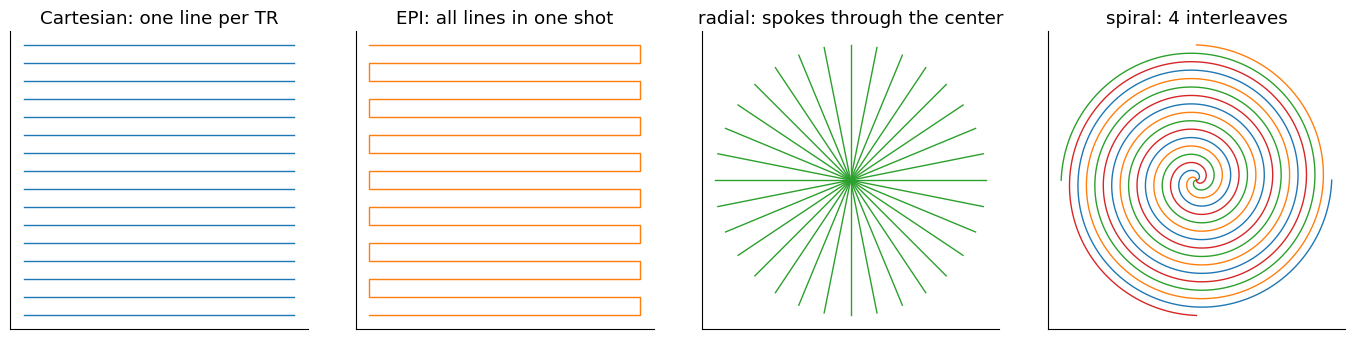

In [11]:
fig, ax = plt.subplots(1, 4, figsize=(14, 3.4))
n = 16
kk = np.linspace(-1, 1, 64)
for j in np.linspace(-1, 1, n): ax[0].plot(kk, np.full_like(kk, j), "C0", lw=1)
ax[0].set_title("Cartesian: one line per TR")
epi_x, epi_y = [], []
for i, j in enumerate(np.linspace(-1, 1, n)):
    epi_x += list(kk if i % 2 == 0 else kk[::-1]); epi_y += [j]*kk.size
ax[1].plot(epi_x, epi_y, "C1", lw=1); ax[1].set_title("EPI: all lines in one shot")
for a in np.linspace(0, np.pi, n, endpoint=False): ax[2].plot(kk*np.cos(a), kk*np.sin(a), "C2", lw=1)
ax[2].set_title("radial: spokes through the center")
tt = np.linspace(0, 1, 2000)
for il in range(4):
    ax[3].plot(tt*np.cos(2*np.pi*4*tt + il*np.pi/2), tt*np.sin(2*np.pi*4*tt + il*np.pi/2), lw=1)
ax[3].set_title("spiral: 4 interleaves")
for a in ax: a.set_aspect("equal"); a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()

*Interpretation:* **EPI** (echo-planar imaging) zig-zags through all of k-space after a single excitation — an image in
~50 ms (P1.5). **Radial** sampling passes through the center every time, which makes it robust to motion. **Spirals**
use the gradients efficiently. Non-Cartesian data need an extra "gridding" step before the FFT.

| ![Radial encoding](../images/radial_encoding-full-Mxy.gif) | ![Spiral encoding](../images/spiral_encoding-full-Mxy.gif) |
| :-: | :-: |
| Radial encoding of $M_{xy}$ | Spiral encoding of $M_{xy}$ |

➡️ **Go deeper:** [F2 K-space](../pass2_deep_dive/F2_K-space.ipynb) · [H2 Fast Imaging Pulse Sequences](../pass2_deep_dive/H2_Fast_Imaging_Pulse_Sequences.ipynb) · [J5 Advanced Image Reconstruction](../pass2_deep_dive/J5_Advanced_Image_Reconstruction.ipynb) (non-Cartesian)

## 7. Field of view and resolution from k-space sampling

Two simple rules follow from the Fourier relationship:

$$FOV = \frac{1}{\Delta k}, \qquad \delta = \frac{1}{2k_{max}} .$$

*In words:* the **spacing** of the k-space samples $\Delta k$ sets how large the image is before it repeats (the
field of view, $FOV$); the **extent** of k-space $\pm k_{max}$ sets the smallest detail (pixel size $\delta$). Both in
metres; $\Delta k$ and $k_{max}$ in m⁻¹. With $N$ samples, $2k_{max} = N\Delta k$, so $FOV = N\delta$.

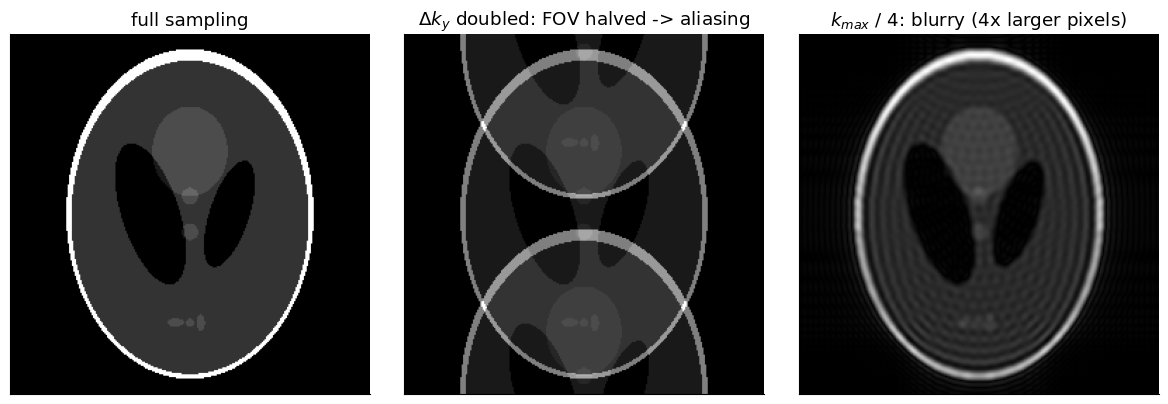

In [12]:
img = mt.shepp_logan(256)
K = mt.fft2c(img)
K_sparse = np.zeros_like(K); K_sparse[::2, :] = K[::2, :]     # every 2nd row: Delta k_y doubled -> FOV_y halved
K_small = K * ((np.abs(kx) < 32) & (np.abs(ky) < 32))          # k_max / 4 -> pixel 4x larger

fig, ax = plt.subplots(1, 3, figsize=(12, 4))
mt.show_image(img, ax=ax[0], title="full sampling")
mt.show_image(2*mt.ifft2c(K_sparse), ax=ax[1], title="$\\Delta k_y$ doubled: FOV halved -> aliasing")
mt.show_image(mt.ifft2c(K_small), ax=ax[2], title="$k_{max}$ / 4: blurry (4x larger pixels)")
plt.tight_layout(); plt.show()

*Interpretation:* sampling k-space too coarsely (middle) makes the FOV smaller than the object, so the parts that stick
out "wrap around" onto the other side — **aliasing** (here, skipping every second line overlaps two copies shifted by
half the original FOV). Not going far enough out in k-space (right) gives a blurry image. *The FOV and resolution of an
MRI image are design choices made through the gradients and the sampling*, not properties of a camera lens.

Let's turn a typical protocol into hardware numbers:

In [13]:
FOV, N = 0.24, 256                     # 24 cm field of view, 256 x 256 matrix
dt = 8e-6                              # dwell time [s]
t_y = 0.5e-3                           # duration of the phase-encode lobe [s]
TR, NEX = 0.5, 1                       # repetition time [s], number of averages

delta = FOV / N
dk = 1 / FOV
kmax = 1 / (2*delta)
BW = 1 / dt
G_read = BW / (mt.GAMMA_BAR * FOV)
G_pe_max = kmax / (mt.GAMMA_BAR * t_y)
print(f"pixel size delta = {delta*1e3:.2f} mm; Delta k = {dk:.2f} 1/m; k_max = {kmax:.0f} 1/m")
print(f"readout: BW = {BW/1e3:.0f} kHz ({BW/N:.0f} Hz/pixel), T_read = {N*dt*1e3:.2f} ms, G_read = {G_read*1e3:.1f} mT/m")
print(f"largest phase-encode gradient (lobe of {t_y*1e3:.1f} ms): {G_pe_max*1e3:.1f} mT/m")
print(f"scan time = TR x N_PE x NEX = {TR} s x {N} x {NEX} = {TR*N*NEX:.0f} s = {TR*N*NEX/60:.1f} min per slice package")

pixel size delta = 0.94 mm; Delta k = 4.17 1/m; k_max = 533 1/m
readout: BW = 125 kHz (488 Hz/pixel), T_read = 2.05 ms, G_read = 12.2 mT/m
largest phase-encode gradient (lobe of 0.5 ms): 25.1 mT/m
scan time = TR x N_PE x NEX = 0.5 s x 256 x 1 = 128 s = 2.1 min per slice package


*Interpretation:* all gradient values are comfortably within the scanner's 40–80 mT/m. The bottleneck is time: one
k-space line per TR means 256 TRs. With a 500 ms TR (needed for T1 contrast, P1.4) that's ~2 minutes. In **2D
multislice** imaging the scanner uses the long TR to excite *other* slices in between (e.g. 20 slices in the same 2
minutes). **3D imaging** excites a thick slab and adds phase encoding along $z$ as well. Making all this *faster* is the
subject of P1.5.

![2D multislice](../images/volumetric_imaging-2D_multislice.png)

*2D multislice imaging: slices are excited interleaved within each TR (figure from Larson's book).*

➡️ **Go deeper:** [G1 FOV and Resolution](../pass2_deep_dive/G1_FOV_and_Resolution.ipynb) · [G3 Cartesian Image Characteristics](../pass2_deep_dive/G3_Cartesian_Image_Characteristics.ipynb) · [H1 Volumetric Imaging](../pass2_deep_dive/H1_Volumetric_Imaging.ipynb) · [I1 Point Spread Function Analysis](../pass2_deep_dive/I1_Point_Spread_Function_Analysis.ipynb) · [RM5 Fourier pairs & sampling](../refreshers/RM5_Fourier_Pairs_and_Sampling.ipynb)

## 8. Try it yourself (optional, interactive)

Choose the size of the sampled k-space region and the sampling step, and see the effect on the image.

In [14]:
try:
    from ipywidgets import interact, IntSlider
    img = mt.shepp_logan(256); K = mt.fft2c(img)
    def explore(k_extent=128, step=1):
        Ks = np.zeros_like(K)
        mask = (np.abs(kx) < k_extent) & (np.abs(ky) < k_extent)
        Ks[::step, :] = (K*mask)[::step, :]
        fig, ax = plt.subplots(1, 2, figsize=(9, 4.3))
        mt.show_kspace(Ks + 1e-9, ax=ax[0], title="sampled k-space")
        mt.show_image(step*mt.ifft2c(Ks), ax=ax[1], title="image"); plt.show()
    interact(explore, k_extent=IntSlider(min=4, max=128, step=4, value=128), step=IntSlider(min=1, max=4, value=1))
except ImportError:
    print("ipywidgets not available - skip this cell")

interactive(children=(IntSlider(value=128, description='k_extent', max=128, min=4, step=4), IntSlider(value=1,…

## Key takeaways

* A **pulse sequence** schedules RF, three gradients and the ADC; $TE$ = excitation → center of k-space, $TR$ = time between excitations.
* **Slice selection**: RF pulse of bandwidth $BW_{rf}$ + gradient $G_{z,SS}$ excites a slab $\Delta z = BW_{rf}/(\bar\gamma G_{z,SS})$.
* **Frequency encoding**: a readout gradient maps position to frequency ($f=\bar\gamma G x$); the FFT separates them, like an ear hearing the notes of a chord.
* **Phase encoding**: a gradient pulse before the readout imprints a stripe-like phase twist; repeated with $N_{PE}$ different amplitudes.
* **k-space** $\vec k(t)=\bar\gamma\int\vec G\,d\tau$: the signal is the Fourier transform of the image, $s(t)=M(\vec k(t))$. Each k-space sample is the weight of one stripe pattern; the image is the inverse FFT.
* Center of k-space → contrast and overall shape; edges → fine detail. $FOV = 1/\Delta k$, $\delta = 1/(2k_{max})$.
* Basic scan time = $TR \times N_{PE} \times NEX$ — the motivation for fast imaging.

## Check your understanding

**1.** With $G_{z,SS}$ = 5 mT/m and an RF pulse bandwidth of 1.5 kHz, how thick is the slice? How do you get a slice
half as thick?

<details><summary>Answer</summary>

$\Delta z = 1500/(42.58\times10^6 \times 0.005)$ = 7.0 mm. Halve it by doubling the gradient (10 mT/m) or halving the
RF bandwidth (e.g. a pulse twice as long with the same TBW).

</details>

**2.** What does a single k-space sample far from the center represent in the image?

<details><summary>Answer</summary>

The amount (magnitude) and position (phase) of one fine stripe pattern spread across the *whole* image. It does not
correspond to any single pixel; it contributes to edges and fine detail everywhere.

</details>

**3.** You want a 20 cm FOV with 1 mm pixels. What $\Delta k$ and $k_{max}$ do you need, and how many phase-encode lines?

<details><summary>Answer</summary>

$\Delta k = 1/FOV$ = 5 m⁻¹; $k_{max} = 1/(2\delta)$ = 500 m⁻¹; $N = FOV/\delta$ = 200 lines (from $-k_{max}$ to
$+k_{max}$ in steps of 5 m⁻¹).

</details>

**4.** Why is the echo time defined as the time at which the center of k-space is acquired?

<details><summary>Answer</summary>

Because the k-space center carries most of the signal energy and determines the image intensity/contrast. The
relaxation state of the magnetization at that moment ($e^{-TE/T_2}$ etc.) therefore sets the image contrast.

</details>

**5.** In the frequency-encoding demo, the signal is largest in the middle of the readout. Why?

<details><summary>Answer</summary>

The negative prewinder lobe first twists the phases (moves to $-k_{max}$); during the readout the positive gradient
unwinds the twist, and at $k_x = 0$ (middle of the readout) all spins are in phase again, giving a **gradient echo**.

</details>

---
*Adapted and extended from P. Larson, "Principles of MRI" (MIT License), chapters "Pulse Sequence", "Spatial Encoding", "K-space", "Slice Selection" and "FOV and Resolution".
Changes: rewritten as an intuitive overview with the piano-chord and stripe-recipe analogies; added Python demos of frequency encoding, Bloch-simulated slice selection, phase-encoding stripes, k-space center/edge reconstructions, trajectories from gradient waveforms, FOV/resolution, and a protocol-to-hardware calculator; all symbols defined.*